# Posterior parameter recovery

Load a saved SBI posterior artifact, run one fresh recovery simulation, then compare stored prior-reference samples with posterior samples. Categorical parameters such as `n_agents` are handled from the artifact metadata instead of being treated as continuous variables.

In [1]:
import copy
import json
import sys
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

try:
    import pandas as pd
except ModuleNotFoundError:
    pd = None

try:
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
except ModuleNotFoundError:
    EventAccumulator = None

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    pass
else:
    plt.style.use("science")

from network_creation.model_inversion import load_posterior_artifact
from network_creation.model_inversion.diagnostics import (
    load_diagnostic_data,
    plot_expected_coverage,
    run_expected_coverage,
)
from network_creation.model_inversion.recovery import (
    observation_from_policy_outputs,
    parameter_recovery_summary,
    plot_parameter_marginals,
    plot_parameter_pairs,
    plot_posterior_ridgelines,
    theta_metadata_rows,
)
from notebooks.utils.table_pretty_print import make_gt_tabs, default_style_gt_table
from tasks.policies import prepare_policy_run


def table(rows):
    return pd.DataFrame(rows) if pd is not None else rows


project_root


PosixPath('/home/hdahmou/Network_creation')

## Load posterior artifact

In [2]:
artifact_root = project_root / "artifacts" / "model_inversion"
artifact_candidates = sorted(
    [
        path
        for path in artifact_root.glob("*")
        if path.is_dir()
        and (path / "metadata.json").is_file()
        and (path / "posterior.pkl").is_file()
    ],
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)
if not artifact_candidates:
    raise FileNotFoundError(f"No complete posterior artifacts found under {artifact_root}")

artifact_options = [
    (str(path.relative_to(project_root)), str(path.relative_to(project_root)))
    for path in artifact_candidates
]
artifact_selector = widgets.Dropdown(
    options=artifact_options,
    value=artifact_options[0][1],
    description="Artifact:",
    layout=widgets.Layout(width="95%"),
)
display(artifact_selector)

Dropdown(description='Artifact:', layout=Layout(width='95%'), options=(('artifacts/model_inversion/mnpe-202605…

In [3]:
artifact_dir = project_root / artifact_selector.value
artifact = load_posterior_artifact(artifact_dir)
metadata = artifact.metadata
dataset_metadata = metadata["dataset"]
prior_samples = artifact.prior_samples
diagnostic_data = load_diagnostic_data(artifact)

artifact_summary = {
    "artifact_dir": str(artifact_dir.relative_to(project_root)),
    "created_at": metadata.get("created_at"),
    "posterior_type": type(artifact.posterior).__name__,
    "sbi_method": metadata.get("sbi", {}).get("method"),
    "n_simulations": dataset_metadata.get("n_simulations"),
    "stored_prior_samples": int(prior_samples.shape[0]),
    "diagnostic_simulations": int(diagnostic_data.theta.shape[0]),
    "x_representation": dataset_metadata.get("x_representation"),
    "x_event_shape": tuple(dataset_metadata.get("x_event_shape", ())),
    "normalize_time": dataset_metadata.get("normalize_time", False),
    "time_axis": dataset_metadata.get("time_axis", "raw_simulator_steps"),
    "step_labels": dataset_metadata.get("step_labels"),
    "final_step_label": dataset_metadata.get("final_step_label"),
}

metadata_tabs = [
    {
        "tab": "Run",
        "title": "Posterior artifact",
        "value": artifact_summary,
    },
    {
        "tab": "Theta",
        "title": "Theta order and parameter types",
        "value": table(theta_metadata_rows(artifact)),
    },
    {
        "tab": "Observations",
        "title": "Observation order",
        "value": table(
            [
                {"index": index, "observable": name}
                for index, name in enumerate(artifact.observation_order)
            ]
        ),
    },
    {
        "tab": "Dropped constants",
        "title": "Dropped constant theta values",
        "value": dataset_metadata.get("constant_theta", {}),
    },
]

display(
    make_gt_tabs(
        metadata_tabs,
        tab_key="tab",
        title_key="title",
        gt_transform=None,
    )
)


## Learning curve

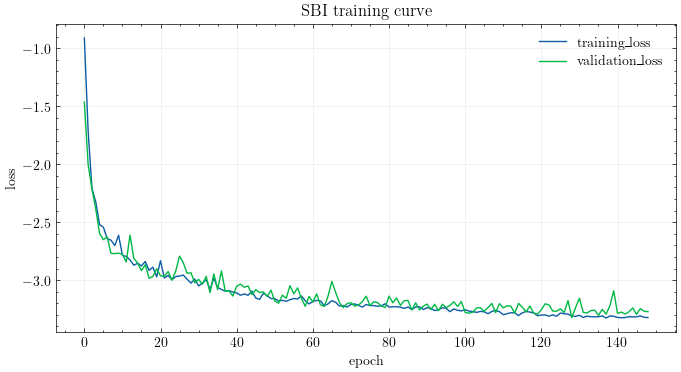

In [4]:
def load_scalars(log_dir, tags=("training_loss", "validation_loss", "epochs_trained", "best_validation_loss")):
    if EventAccumulator is None or not log_dir.is_dir():
        return {}
    accumulator = EventAccumulator(str(log_dir))
    accumulator.Reload()
    available = set(accumulator.Tags().get("scalars", []))
    return {
        tag: {
            "step": np.asarray([event.step for event in accumulator.Scalars(tag)]),
            "value": np.asarray([event.value for event in accumulator.Scalars(tag)]),
        }
        for tag in tags
        if tag in available
    }


learning_scalars = load_scalars(artifact.tensorboard_log_dir)
curve_tags = [tag for tag in ("training_loss", "validation_loss") if tag in learning_scalars]

if not learning_scalars:
    display(Markdown(f"No TensorBoard scalar logs found under `{artifact.tensorboard_log_dir}`."))
else:
    if curve_tags:
        fig, ax = plt.subplots(figsize=(8, 4))
        for tag in curve_tags:
            curve = learning_scalars[tag]
            ax.plot(curve["step"], curve["value"], label=tag)
        ax.set_xlabel("epoch")
        ax.set_ylabel("loss")
        ax.set_title("SBI training curve")
        ax.legend()
        ax.grid(alpha=0.25)
        plt.show()

    display(
        make_gt_tabs(
            [
                {
                    "tab": "",
                    "title": "Learning scalar summary",
                    "value": table(
                        [
                            {
                                "tag": tag,
                                "n_points": len(curve["value"]),
                                "first": float(curve["value"][0]),
                                "last": float(curve["value"][-1]),
                                "min": float(np.min(curve["value"])),
                                "max": float(np.max(curve["value"])),
                            }
                            for tag, curve in learning_scalars.items()
                            if len(curve["value"])
                        ]
                    ),
                }
            ],
            tab_key="tab",
            title_key="title",
            gt_transform=default_style_gt_table,
        )
    )

## Parameter recovery

In [5]:
RECOVERY_PARAMETER_SEED = 42
RECOVERY_N_EPISODES = None
POSTERIOR_SAMPLE_SEED = 42
NUM_POSTERIOR_SAMPLES = 2**9
MAX_SAMPLING_TIME_SECONDS = 60
POSTERIOR_DEVICE = "cpu"
EXPECTED_COVERAGE_POSTERIOR_SAMPLES = 1000
DIAGNOSTIC_NUM_WORKERS = 1
RIDGELINE_DIAGNOSTIC_CASES = 20
RIDGELINE_POSTERIOR_SAMPLES = 2**8


In [6]:
theta_names = list(artifact.theta_order)


def resolve_existing_path(raw_path):
    path = Path(raw_path).expanduser()
    candidates = [path]
    if not path.is_absolute():
        candidates.extend([project_root / path, artifact_dir / path])
    return next((candidate.resolve() for candidate in candidates if candidate.exists()), path.resolve())


def n_agents_values(raw_n_agents):
    if isinstance(raw_n_agents, dict):
        if raw_n_agents.get("kind") != "sampled_discrete_range":
            raise ValueError(f"Unsupported n_agents spec: {raw_n_agents}")
        return list(range(int(raw_n_agents["min"]), int(raw_n_agents["max"]) + 1, int(raw_n_agents.get("step", 1))))
    if isinstance(raw_n_agents, list):
        return [int(value) for value in raw_n_agents]
    return [int(raw_n_agents)]


def build_recovery_config(source_config, *, seed, n_episodes=None):
    config = copy.deepcopy(source_config)
    rng = np.random.default_rng(seed)
    population = config["population"]
    proportion_spec = population["policy_proportions"]

    population["n_agents"] = int(rng.choice(n_agents_values(population["n_agents"])))
    proportion_spec["values"] = [float(rng.choice(proportion_spec["values"]))]
    config["sampling"]["log2_budget"] = 0
    config["sampling"]["seed"] = int(seed)
    config["simulator"]["seed"] = int(source_config["simulator"]["seed"]) + 10000
    if n_episodes is not None:
        config["simulator"]["n_episodes"] = int(n_episodes)

    return config, {
        "recovery_parameter_seed": seed,
        "n_agents": population["n_agents"],
        "policy_proportion": proportion_spec["values"][0],
        "simulator_seed": config["simulator"]["seed"],
        "n_episodes": config["simulator"]["n_episodes"],
    }


def theta_from_configuration(prepared, configuration, theta_order):
    values_by_name = {
        name: float(configuration[index])
        for name, index in prepared.sweep.column_index_by_name.items()
    }
    missing = [name for name in theta_order if name not in values_by_name]
    if missing:
        raise KeyError(f"Theta names missing from recovery config: {missing}")
    return np.asarray([values_by_name[name] for name in theta_order], dtype=np.float32)


source_config_path = resolve_existing_path(dataset_metadata["config_path"])
source_config = json.loads(source_config_path.read_text(encoding="utf-8"))
recovery_config, recovery_choices = build_recovery_config(
    source_config,
    seed=RECOVERY_PARAMETER_SEED,
    n_episodes=RECOVERY_N_EPISODES,
)
display(recovery_choices)

{'recovery_parameter_seed': 42,
 'n_agents': 10,
 'policy_proportion': 1.0,
 'simulator_seed': 10011,
 'n_episodes': 16}

In [7]:
prepared_recovery = prepare_policy_run(recovery_config)
recovery_outputs = prepared_recovery.run(0)
recovery_configuration = prepared_recovery.sweep.configuration_at(0)

true_theta = theta_from_configuration(prepared_recovery, recovery_configuration, theta_names)
recovery_x = observation_from_policy_outputs(
    recovery_outputs,
    artifact,
    n_agents=int(recovery_choices["n_agents"]),
    n_actors=int(recovery_config["simulator"]["actor_scheduler"]["n_actors"]),
)
expected_x_shape = tuple(dataset_metadata["x_event_shape"])
if tuple(recovery_x.shape) != expected_x_shape:
    raise ValueError(f"recovery_x shape {tuple(recovery_x.shape)} does not match expected shape {expected_x_shape}")

display(
    make_gt_tabs(
        [
            {
                "tab": "True theta",
                "title": "Recovery target",
                "value": table(
                    [
                        {
                            "theta": name,
                            "type": "categorical" if artifact.is_discrete_theta(name) else "continuous",
                            "true_value": int(round(value)) if artifact.is_discrete_theta(name) else float(value),
                        }
                        for name, value in zip(theta_names, true_theta, strict=False)
                    ]
                ),
            },
            {"tab": "x", "title": "Recovery observation", "value": {"shape": tuple(recovery_x.shape), "values": recovery_x.tolist()}},
        ],
        tab_key="tab",
        title_key="title",
        gt_transform=default_style_gt_table,
    )
)

In [8]:
posterior_samples, theta_names = artifact.sample(
    recovery_x,
    num_samples=NUM_POSTERIOR_SAMPLES,
    seed=POSTERIOR_SAMPLE_SEED,
    device=POSTERIOR_DEVICE,
    max_sampling_time=MAX_SAMPLING_TIME_SECONDS,
    return_partial_on_timeout=True,
    show_progress_bars=True,
)
if posterior_samples.shape[0] == 0:
    raise RuntimeError("Posterior sampling returned no samples before max_sampling_time.")

display(
    {
        "requested_posterior_samples": NUM_POSTERIOR_SAMPLES,
        "returned_posterior_samples": int(posterior_samples.shape[0]),
        "stored_prior_samples": int(prior_samples.shape[0]),
        "theta_dim": int(posterior_samples.shape[1]),
    }
)

  0%|          | 0/512 [00:00<?, ?it/s]

/home/hdahmou/Network_creation/.venv/lib/python3.13/site-packages/nflows/transforms/lu.py:80: UserWarning: torch.triangular_solve is deprecated in favor of torch.linalg.solve_triangularand will be removed in a future PyTorch release.
torch.linalg.solve_triangular has its arguments reversed and does not return a copy of one of the inputs.
X = torch.triangular_solve(B, A).solution
should be replaced with
X = torch.linalg.solve_triangular(A, B). (Triggered internally at ../aten/src/ATen/native/BatchLinearAlgebra.cpp:2190.)
  outputs, _ = torch.triangular_solve(


{'requested_posterior_samples': 512,
 'returned_posterior_samples': 512,
 'stored_prior_samples': 4096,
 'theta_dim': 3}

In [9]:
display(
    make_gt_tabs(
        [
            {
                "tab": "",
                "title": "Recovery summary",
                "value": table(
                    parameter_recovery_summary(
                        artifact,
                        true_theta=true_theta,
                        posterior_samples=posterior_samples,
                    )
                ),
            }
        ],
        tab_key="tab",
        title_key="title",
        gt_transform=default_style_gt_table,
    )
)

## Diagnostics


/home/hdahmou/Network_creation/.venv/lib/python3.13/site-packages/sbi/utils/diagnostics_utils.py:45: UserWarning: Capping max_sampling_batch_size from 10000 to 500 to avoid excessive memory usage.
  posterior_samples = posterior.sample_batched(


Drawing 1000 samples for 200 observations:   0%|          | 0/1000 [00:00<?, ?it/s]

Calculating ranks for 200 SBC samples:   0%|          | 0/200 [00:00<?, ?it/s]

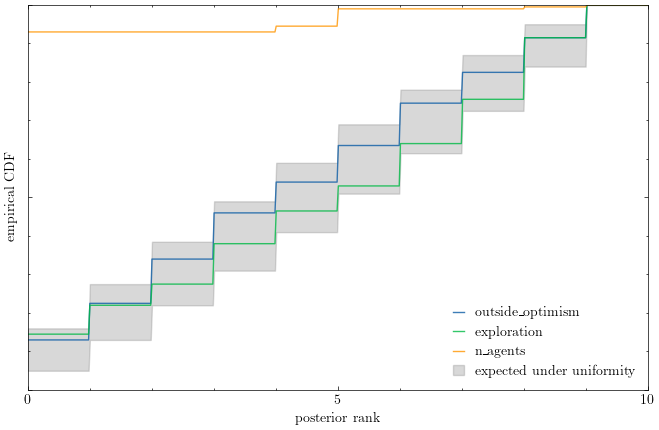

{'diagnostic_simulations': 200, 'posterior_samples_per_simulation': 1000}

In [10]:
coverage = run_expected_coverage(
    artifact,
    diagnostic_data,
    num_posterior_samples=EXPECTED_COVERAGE_POSTERIOR_SAMPLES,
    num_workers=DIAGNOSTIC_NUM_WORKERS,
    show_progress_bar=True,
)
fig, ax = plot_expected_coverage(artifact, coverage)
plt.show()

display(
    {
        "diagnostic_simulations": coverage["n_diagnostic_simulations"],
        "posterior_samples_per_simulation": coverage["num_posterior_samples"],
    }
)


## Posterior ridgelines

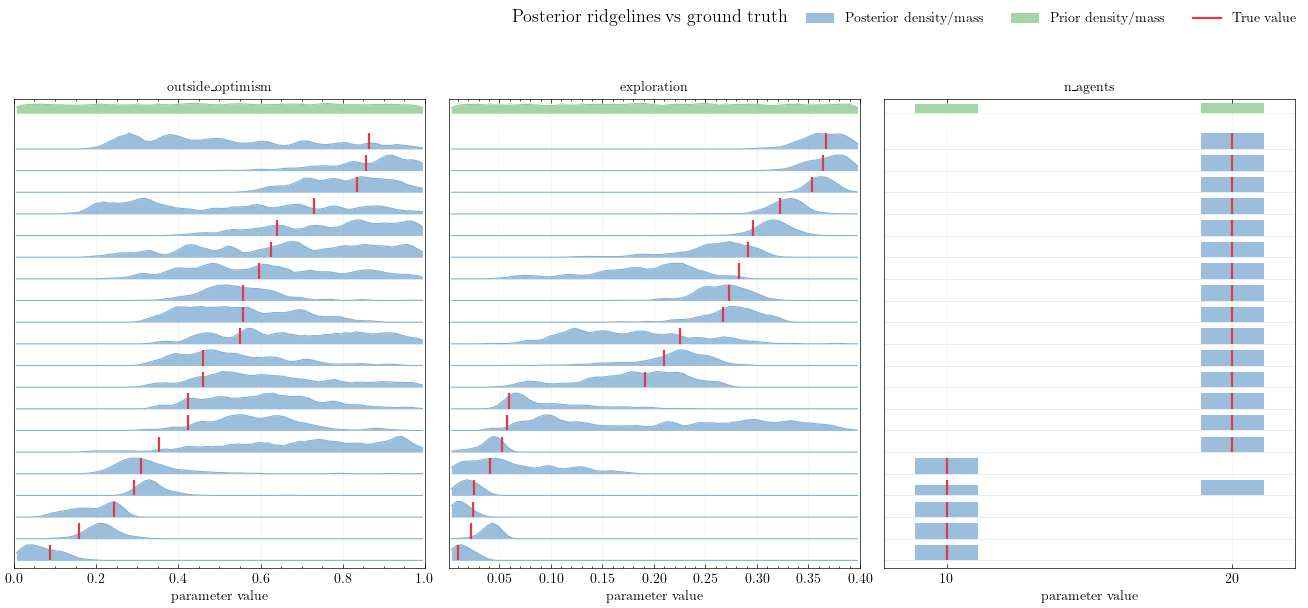

In [11]:
ridgeline_count = min(RIDGELINE_DIAGNOSTIC_CASES, diagnostic_data.theta.shape[0])
ridgeline_rng = np.random.default_rng(POSTERIOR_SAMPLE_SEED)
ridgeline_indices = np.sort(
    ridgeline_rng.choice(
        diagnostic_data.theta.shape[0],
        size=ridgeline_count,
        replace=False,
    )
)

ridgeline_samples = []
for offset, index in enumerate(ridgeline_indices):
    samples, _ = artifact.sample(
        diagnostic_data.x[index],
        num_samples=RIDGELINE_POSTERIOR_SAMPLES,
        seed=POSTERIOR_SAMPLE_SEED + offset,
        device=POSTERIOR_DEVICE,
        max_sampling_time=MAX_SAMPLING_TIME_SECONDS,
        return_partial_on_timeout=True,
        show_progress_bars=False,
    )
    if samples.shape[0] == 0:
        raise RuntimeError(f"Posterior sampling returned no samples for diagnostic row {index}.")
    ridgeline_samples.append(samples)

ridgeline_sample_count = min(sample.shape[0] for sample in ridgeline_samples)
ridgeline_posterior_samples = np.asarray(
    [sample[:ridgeline_sample_count] for sample in ridgeline_samples],
    dtype=np.float32,
)
ridgeline_true_theta = diagnostic_data.theta[ridgeline_indices]

fig = plot_posterior_ridgelines(
    artifact,
    prior_samples=prior_samples,
    posterior_samples=ridgeline_posterior_samples,
    true_theta=ridgeline_true_theta,
)
plt.show()


## Prior versus posterior

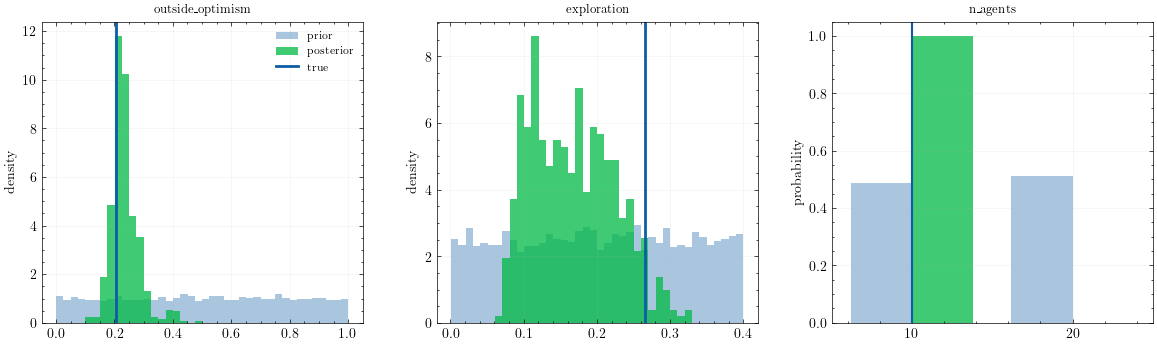

In [12]:
fig = plot_parameter_marginals(
    artifact,
    prior_samples=prior_samples,
    posterior_samples=posterior_samples,
    true_theta=true_theta,
)
base_size = 4
fig.set_size_inches(base_size * len(theta_names), base_size)
plt.show()

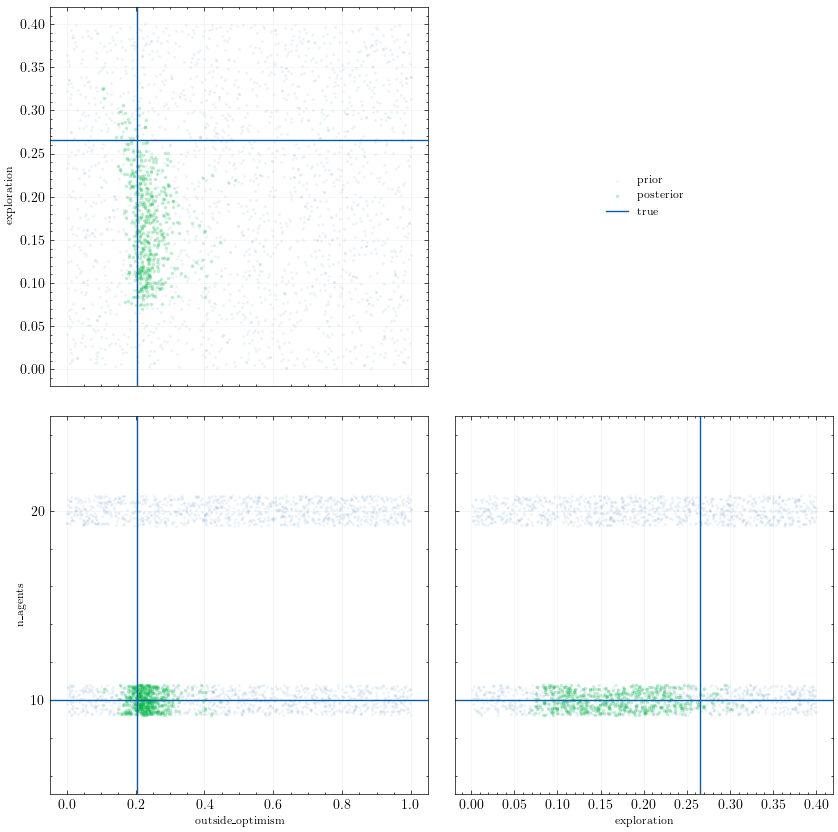

In [13]:
if len(artifact.theta_order) < 2:
    display(Markdown("Pair plot requires at least two theta dimensions."))
else:
    fig = plot_parameter_pairs(
        artifact,
        prior_samples=prior_samples,
        posterior_samples=posterior_samples,
        true_theta=true_theta,
        seed=POSTERIOR_SAMPLE_SEED,
    )
    base_size = 3
    fig.set_size_inches(base_size * len(theta_names), base_size* len(theta_names))
    plt.show()